In [1]:

from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

train_dir = project_dir / "data" / "processed" / "train"
val_dir = project_dir / "data" / "processed" / "val"

train_files = sorted(train_dir.glob("*.npz"))
val_files = sorted(val_dir.glob("*.npz"))

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Training patches:", len(train_files))
print("Validation patches:", len(val_files))


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Training patches: 294
Validation patches: 196


In [2]:

class SARTrackDataset(Dataset):
    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        with np.load(self.files[idx]) as data:
            x = data["x"].astype(np.float32)
            y = data["y"].astype(np.int64)

        return torch.from_numpy(x), torch.from_numpy(y)


train_loader = DataLoader(
    SARTrackDataset(train_files),
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    SARTrackDataset(val_files),
    batch_size=4,
    shuffle=False,
    num_workers=0
)

images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Classes:", torch.unique(masks))


Images: torch.Size([4, 2, 128, 128])
Masks: torch.Size([4, 128, 128])
Classes: tensor([  0,   1,   2,   3,   4, 255])


In [3]:

import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(2, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.bottleneck = DoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        self.dec3 = DoubleConv(128 + 64, 64)
        self.dec2 = DoubleConv(64 + 32, 32)
        self.dec1 = DoubleConv(32 + 16, 16)

        self.output = nn.Conv2d(16, 5, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = F.interpolate(b, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


model = UNet().to(device)

with torch.no_grad():
    output = model(images.to(device))

print("Model output:", output.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Model output: torch.Size([4, 5, 128, 128])
Parameters: 488629


In [4]:

# Training class frequencies (from Day 4)
freq = torch.tensor(
    [0.0062, 0.3607, 0.1347, 0.0946, 0.4037],
    dtype=torch.float32
)

# Balance rare classes without extreme weights
weights = 1.0 / torch.sqrt(freq)
weights = (weights / weights.mean()).clamp(max=5.0).to(device)

criterion = nn.CrossEntropyLoss(
    weight=weights,
    ignore_index=255
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Class weights:", weights.cpu().numpy().round(3))
print("Loss: Weighted CrossEntropy")
print("Optimizer: Adam")


Class weights: [2.898 0.38  0.622 0.742 0.359]
Loss: Weighted CrossEntropy
Optimizer: Adam


In [5]:

# First U-Net training test — 3 epochs
model_dir = project_dir / "models"
model_dir.mkdir(exist_ok=True)

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")

for epoch in range(3):
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        predictions = model(x)
        loss = criterion(predictions, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            predictions = model(x)
            loss = criterion(predictions, y)
            val_loss += loss.item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(),
                   model_dir / "best_unet.pth")

    print(
        f"Epoch {epoch+1}/3 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}",
        flush=True
    )

print("Training test complete!")
print("Best model saved:", model_dir / "best_unet.pth")


Epoch 1/3 | Train Loss: 1.2244 | Val Loss: 1.0602
Epoch 2/3 | Train Loss: 0.9714 | Val Loss: 0.9568
Epoch 3/3 | Train Loss: 0.8893 | Val Loss: 1.1966
Training test complete!
Best model saved: c:\Users\admin\Downloads\Deep learning\Project\models\best_unet.pth


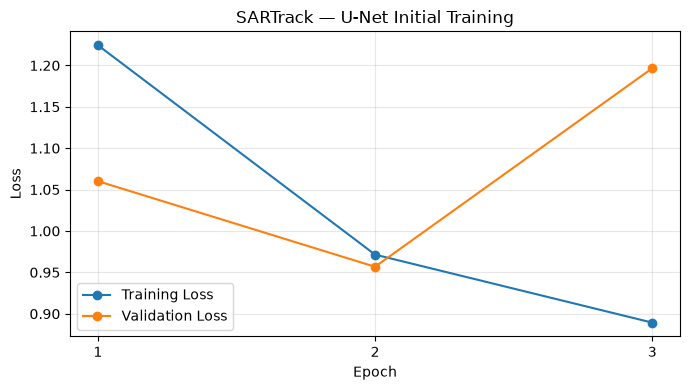

In [6]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], "o-", label="Training Loss")
plt.plot(epochs, history["val_loss"], "o-", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SARTrack — U-Net Initial Training")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(model_dir / "initial_training_loss.png", dpi=200)
plt.show()


In [7]:

# Evaluate the best saved U-Net model
model.load_state_dict(
    torch.load(model_dir / "best_unet.pth",
               map_location=device, weights_only=True)
)
model.eval()

confusion = torch.zeros((5, 5), dtype=torch.int64)

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        preds = model(x).argmax(dim=1).cpu()

        valid = y != 255
        target = y[valid]
        predicted = preds[valid]

        indices = target * 5 + predicted
        confusion += torch.bincount(
            indices, minlength=25
        ).reshape(5, 5)

tp = confusion.diag().float()
support = confusion.sum(dim=1).float()
predicted_count = confusion.sum(dim=0).float()

iou = tp / (support + predicted_count - tp).clamp(min=1)
f1 = 2 * tp / (support + predicted_count).clamp(min=1)

accuracy = tp.sum() / confusion.sum().clamp(min=1)

names = ["Water", "Trees", "Grass", "Crops", "Built-up"]

print(f"Overall Accuracy: {accuracy.item()*100:.2f}%")
print(f"Mean IoU: {iou.mean().item()*100:.2f}%")
print(f"Macro F1: {f1.mean().item()*100:.2f}%")

for name, a, b in zip(names, iou, f1):
    print(f"{name}: IoU={a.item()*100:.2f}% | F1={b.item()*100:.2f}%")


Overall Accuracy: 85.47%
Mean IoU: 42.81%
Macro F1: 56.58%
Water: IoU=25.09% | F1=40.11%
Trees: IoU=47.58% | F1=64.48%
Grass: IoU=27.14% | F1=42.69%
Crops: IoU=26.91% | F1=42.40%
Built-up: IoU=87.32% | F1=93.23%


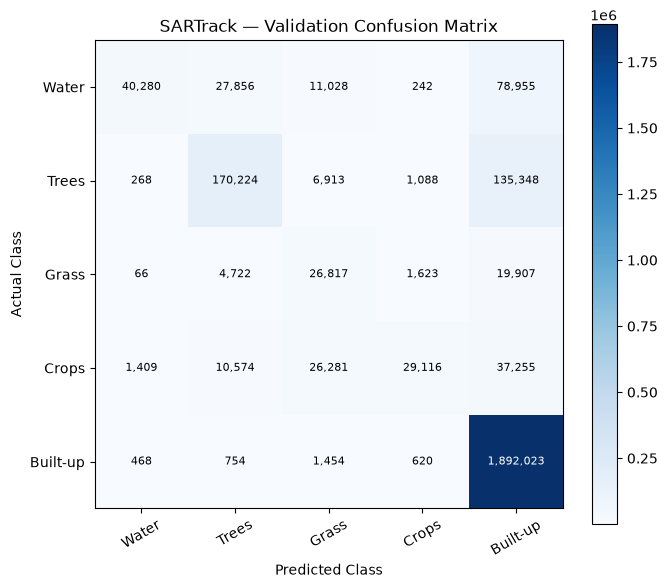

In [8]:

import matplotlib.pyplot as plt
import numpy as np

cm = confusion.numpy()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(5), names, rotation=30)
ax.set_yticks(range(5), names)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
ax.set_title("SARTrack — Validation Confusion Matrix")

for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:,}",
                ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max()/2 else "black")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(model_dir / "confusion_matrix.png", dpi=200)
plt.show()


In [9]:

water_patches = 0

for file in train_files:
    with np.load(file) as data:
        y = data["y"]

    if np.any(y == 0):
        water_patches += 1

print("Total training patches:", len(train_files))
print("Patches containing Water:", water_patches)
print("Patches without Water:", len(train_files) - water_patches)


Total training patches: 294
Patches containing Water: 100
Patches without Water: 194


In [10]:

water_percentages = []

for file in train_files:
    with np.load(file) as data:
        y = data["y"]

    valid = y != 255
    if valid.any():
        water_pct = 100 * np.sum(y == 0) / np.sum(valid)
        water_percentages.append(water_pct)

water_percentages = np.array(water_percentages)

print("Patches with >5% Water:", np.sum(water_percentages > 5))
print("Patches with >20% Water:", np.sum(water_percentages > 20))
print("Maximum Water in one patch:", round(water_percentages.max(), 2), "%")


Patches with >5% Water: 10
Patches with >20% Water: 0
Maximum Water in one patch: 12.6 %


In [11]:

from torch.utils.data import WeightedRandomSampler

sample_weights = []

for file in train_files:
    with np.load(file) as data:
        y = data["y"]

    valid = y != 255
    water_fraction = np.sum(y == 0) / max(np.sum(valid), 1)

    weight = 1.0 + 4.0 * min(water_fraction / 0.10, 1.0)
    sample_weights.append(weight)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_files),
    replacement=True
)

balanced_loader = DataLoader(
    SARTrackDataset(train_files),
    batch_size=4,
    sampler=sampler,
    num_workers=0
)

print("Water-aware DataLoader ready!")
print("Training samples per epoch:", len(sampler))


Water-aware DataLoader ready!
Training samples per epoch: 294


In [12]:

# Experiment 2: Water-aware sampling
# Fresh model; original baseline remains unchanged

torch.manual_seed(42)

model_v2 = UNet().to(device)
optimizer_v2 = torch.optim.Adam(model_v2.parameters(), lr=0.001)

history_v2 = {"train_loss": [], "val_loss": []}
best_val_v2 = float("inf")

for epoch in range(3):
    model_v2.train()
    train_total = 0.0

    for x, y in balanced_loader:
        x, y = x.to(device), y.to(device)

        optimizer_v2.zero_grad()
        loss = criterion(model_v2(x), y)
        loss.backward()
        optimizer_v2.step()

        train_total += loss.item()

    model_v2.eval()
    val_total = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            val_total += criterion(model_v2(x), y).item()

    train_loss = train_total / len(balanced_loader)
    val_loss = val_total / len(val_loader)

    history_v2["train_loss"].append(train_loss)
    history_v2["val_loss"].append(val_loss)

    if val_loss < best_val_v2:
        best_val_v2 = val_loss
        torch.save(model_v2.state_dict(),
                   model_dir / "best_unet_v2.pth")

    print(f"Epoch {epoch+1}/3 | "
          f"Train: {train_loss:.4f} | Val: {val_loss:.4f}",
          flush=True)

print("Experiment 2 complete!")
print("Saved: best_unet_v2.pth")


Epoch 1/3 | Train: 1.2757 | Val: 0.8512
Epoch 2/3 | Train: 0.9884 | Val: 1.0998
Epoch 3/3 | Train: 0.8683 | Val: 0.7791
Experiment 2 complete!
Saved: best_unet_v2.pth


In [13]:

# Evaluate improved U-Net (v2)
model_v2.load_state_dict(
    torch.load(model_dir / "best_unet_v2.pth",
               map_location=device, weights_only=True)
)
model_v2.eval()

confusion_v2 = torch.zeros((5, 5), dtype=torch.int64)

with torch.no_grad():
    for x, y in val_loader:
        preds = model_v2(x.to(device)).argmax(1).cpu()

        valid = y != 255
        indices = y[valid] * 5 + preds[valid]

        confusion_v2 += torch.bincount(
            indices, minlength=25
        ).reshape(5, 5)

tp = confusion_v2.diag().float()
actual = confusion_v2.sum(1).float()
predicted = confusion_v2.sum(0).float()

iou_v2 = tp / (actual + predicted - tp).clamp(min=1)
f1_v2 = 2 * tp / (actual + predicted).clamp(min=1)
accuracy_v2 = tp.sum() / confusion_v2.sum()

print(f"Accuracy: {accuracy_v2.item()*100:.2f}%")
print(f"mIoU: {iou_v2.mean().item()*100:.2f}%")
print(f"Macro F1: {f1_v2.mean().item()*100:.2f}%")

for name, score in zip(names, iou_v2):
    print(f"{name} IoU: {score.item()*100:.2f}%")


Accuracy: 86.48%
mIoU: 49.27%
Macro F1: 62.61%
Water IoU: 41.13%
Trees IoU: 61.41%
Grass IoU: 21.67%
Crops IoU: 31.55%
Built-up IoU: 90.57%


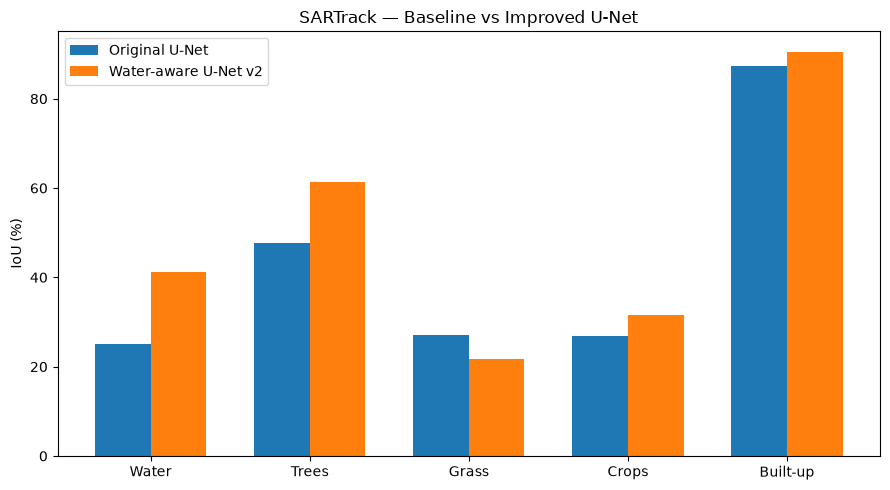

In [14]:

import matplotlib.pyplot as plt
import numpy as np

baseline = iou.cpu().numpy() * 100
improved = iou_v2.cpu().numpy() * 100

x = np.arange(5)
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, baseline, width, label="Original U-Net")
plt.bar(x + width/2, improved, width, label="Water-aware U-Net v2")

plt.xticks(x, names)
plt.ylabel("IoU (%)")
plt.title("SARTrack — Baseline vs Improved U-Net")
plt.legend()
plt.tight_layout()

plt.savefig(model_dir / "model_comparison.png", dpi=200)
plt.show()


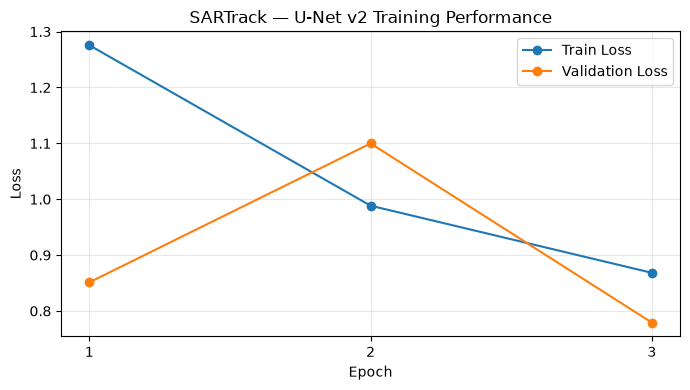

In [15]:

import matplotlib.pyplot as plt

epochs = range(1, len(history_v2["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history_v2["train_loss"], "o-", label="Train Loss")
plt.plot(epochs, history_v2["val_loss"], "o-", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SARTrack — U-Net v2 Training Performance")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(model_dir / "unet_v2_training_loss.png", dpi=200)
plt.show()


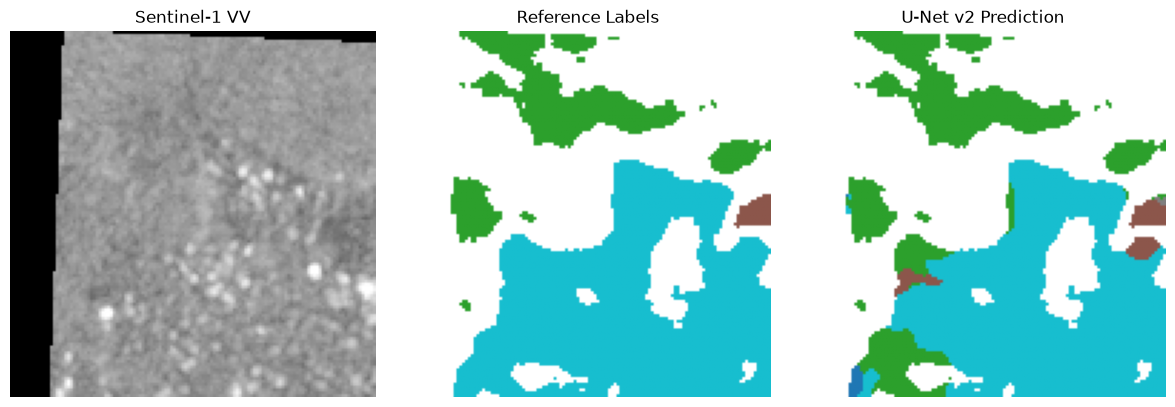

In [16]:

# Visual comparison: SAR input, reference labels, prediction
import matplotlib.pyplot as plt
import numpy as np

model_v2.eval()

x, y = next(iter(val_loader))

with torch.no_grad():
    pred = model_v2(x.to(device)).argmax(1).cpu()

i = 0

sar = x[i, 0].numpy()
truth = y[i].numpy()
prediction = pred[i].numpy()

# Hide ignored pixels in both maps
truth_map = np.ma.masked_where(truth == 255, truth)
prediction_map = np.ma.masked_where(truth == 255, prediction)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(sar, cmap="gray")
axes[0].set_title("Sentinel-1 VV")

axes[1].imshow(truth_map, cmap="tab10", vmin=0, vmax=4)
axes[1].set_title("Reference Labels")

axes[2].imshow(prediction_map, cmap="tab10", vmin=0, vmax=4)
axes[2].set_title("U-Net v2 Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(model_dir / "unet_v2_prediction_example.png", dpi=200)
plt.show()
